In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, Adam, RMSprop

In [ ]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
x_train=x_train/255.0
x_test=x_test/255.0

Entry 0: Label = 5
Data shape: (28, 28)

Entry 1: Label = 0
Data shape: (28, 28)



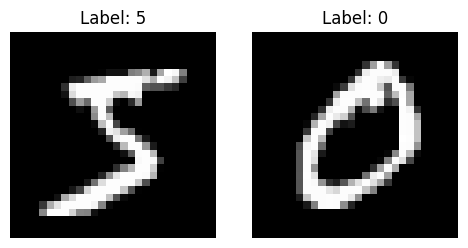

In [ ]:
import matplotlib.pyplot as plt

# Print labels and dimensions for the first two data entries
for i in range(2):
    print(f"Entry {i}: Label = {y_train[i]}")
    print(f"Data shape: {x_train[i].shape}\n")

# Visualize the first two images
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
for i in range(2):
    axes[i].imshow(x_train[i], cmap='gray')
    axes[i].set_title(f"Label: {y_train[i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

def create_model(activation_func, optimizer):
  model = Sequential([
      Dense(128, activation=activation_func, input_shape=(784,)),
      Dense(64, activation=activation_func),
      Dense(10, activation='softmax')
  ])

  model.compile(
      optimizer=optimizer,
      loss='sparse_categorical_crossentropy',
      metrics=['accuracy']
  )
  return model


activations = ['relu', 'sigmoid', 'tanh']
for activation in activations:
  print('\nActivation Function:', activation)
  for optimizer in ['sgd', 'adam', 'rmsprop']:
    print(optimizer)
    model = create_model(activation, optimizer)


Activation Function: relu
sgd
adam
rmsprop


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Activation Function: sigmoid
sgd
adam
rmsprop

Activation Function: tanh
sgd
adam
rmsprop


In [ ]:
# Use a specific activation function string like 'relu' instead of the global 'activation' list variable
model = create_model('relu', 'adam')
model.fit(x_train, y_train, epochs=3, batch_size=32, verbose=1)
loss, accuracy = model.evaluate(x_test, y_test)
print(f'Test Loss: {loss}, Test Accuracy: {accuracy}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9280 - loss: 0.2439
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9692 - loss: 0.1019
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9783 - loss: 0.0700
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9771 - loss: 0.0775
Test Loss: 0.07751688361167908, Test Accuracy: 0.9771000146865845


In [ ]:
optimizers = {
    'sgd': SGD(learning_rate=0.01),
    'adam': Adam(learning_rate=0.001),
    'rmsprop': RMSprop(learning_rate=0.001)
}
for name, optimizer in optimizers.items():
  print('\nOptimizer:',name)
  model = create_model('relu', optimizer)
  model.fit(x_train, y_train, epochs=3, batch_size=32, verbose=1)
  loss, accuracy = model.evaluate(x_test, y_test)
  print('test accuracy',accuracy)


Optimizer: sgd


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8315 - loss: 0.6363
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9152 - loss: 0.2965
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9315 - loss: 0.2420
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9365 - loss: 0.2104
test accuracy 0.9365000128746033

Optimizer: adam
Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9303 - loss: 0.2395
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9686 - loss: 0.1043
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9780 - loss: 0.0713
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9751 - loss: 0.0804
test accuracy 0.9750999808311462

Optimizer: rmsprop
Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9286 - loss: 0.2417
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9688 - loss: 0.1054
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 6

In [ ]:
model=create_model('relu','adam')
model.fit(x_train,y_train,epochs=3,batch_size=32,verbose=1)
loss,accuracy=model.evaluate(x_test,y_test)

loss,accuracy=model.evaluate(x_test,y_test)
print(f'Test Loss: {loss}, Test Accuracy: {accuracy}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9302 - loss: 0.2419
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9702 - loss: 0.0989
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9789 - loss: 0.0671
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9748 - loss: 0.0844
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9748 - loss: 0.0844
Test Loss: 0.08439729362726212, Test Accuracy: 0.9747999906539917
